# EcoSort AI: RealWaste download and inspection

Goal: download RealWaste, inspect its quality, and identify likely duplicate/near-duplicate images **before splitting or training**.

Dataset citation: Single, S., Iranmanesh, S., & Raad, R. (2023). *RealWaste* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5SS4G

**License caution:** UCI currently lists CC BY 4.0, while the original project repository and IEEE DataPort listing state CC BY-NC-SA 4.0. These terms conflict. Until the dataset authors clarify which terms apply to the downloaded archive, do not assume commercial-use permission; document the discrepancy and use the more restrictive interpretation. See the README sources linked in this notebook.

This notebook saves the raw data and manifest under the same project folder used by notebook 02.


In [1]:
import os, zipfile, hashlib, urllib.request, sys, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ImageHash is used for perceptual hashing (not just exact hash equality).
try:
    import imagehash
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ImageHash"])
    import imagehash

# In Colab, keep the dataset and manifest after a runtime reset.
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/ecosort")
else:
    BASE_DIR = Path(".")
BASE_DIR.mkdir(parents=True, exist_ok=True)

RAW_DIR = BASE_DIR / "data_raw"
MANIFEST_PATH = BASE_DIR / "manifest.csv"
URL = "https://archive.ics.uci.edu/static/public/908/realwaste.zip"


Mounted at /content/drive


## 1. Download and unzip
If this cell fails (network or URL change), download the zip manually from https://archive.ics.uci.edu/dataset/908/realwaste, upload it to Colab, and unzip into `data_raw/`.

In [2]:
RAW_DIR.mkdir(parents=True, exist_ok=True)
if not any(RAW_DIR.iterdir()):
    zip_path = BASE_DIR / "realwaste.zip"
    req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open(zip_path, "wb") as f:
        f.write(r.read())
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(RAW_DIR)
print("Extracted to", RAW_DIR.resolve())


Extracted to /content/drive/MyDrive/ecosort/data_raw


## 2. Locate the class folders
Each subfolder of the `RealWaste` directory should be one class.

In [3]:
def find_class_root(base: Path) -> Path:
    for p in base.rglob("*"):
        if p.is_dir() and p.name == "RealWaste":
            subdirs = [d for d in p.iterdir() if d.is_dir()]
            if subdirs:
                return p
    raise FileNotFoundError("Could not find a RealWaste folder with class subfolders")

DATA_DIR = find_class_root(RAW_DIR)
classes = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())
print("Data dir:", DATA_DIR)
print(len(classes), "classes:", classes)

Data dir: /content/drive/MyDrive/ecosort/data_raw/realwaste-main/RealWaste
9 classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


## 3. Build a manifest (one row per image)

For every file, record its class, relative path, dimensions, mode, mean brightness, MD5 hash (exact byte duplicates), difference hash, and perceptual hash (pHash). Files that fail to open are flagged as corrupted.

The pHash is used to identify **candidate near-duplicates**. A Hamming-distance threshold of 4/64 is deliberately conservative; inspect flagged groups rather than assuming every candidate is a duplicate.


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

rows = []
for cls in classes:
    for path in sorted((DATA_DIR / cls).iterdir()):
        if path.suffix.lower() not in IMG_EXT:
            continue
        row = {
            "class": cls,
            "path": str(path),
            "relative_path": f"{cls}/{path.name}",
            "corrupted": False,
        }
        try:
            row["md5"] = hashlib.md5(path.read_bytes()).hexdigest()
            with Image.open(path) as im:
                im.verify()
            with Image.open(path) as im:
                im.load()
                row["width"], row["height"] = im.size
                row["mode"] = im.mode
                row["brightness"] = float(np.asarray(im.convert("L")).mean())
                row["dhash"] = str(imagehash.dhash(im))
                row["phash"] = str(imagehash.phash(im))
        except Exception as e:
            row["corrupted"] = True
            row["error"] = str(e)
        rows.append(row)

df = pd.DataFrame(rows)

# Build connected groups of perceptually similar images using a BK-tree.
# This avoids comparing every image with every other image in Python.
class BKNode:
    def __init__(self, value, index):
        self.value = value
        self.indices = [index]
        self.children = {}

class BKTree:
    def __init__(self):
        self.root = None
    @staticmethod
    def distance(a, b):
        return (a ^ b).bit_count()
    def add(self, value, index):
        if self.root is None:
            self.root = BKNode(value, index)
            return
        node = self.root
        while True:
            d = self.distance(value, node.value)
            if d == 0:
                node.indices.append(index)
                return
            if d not in node.children:
                node.children[d] = BKNode(value, index)
                return
            node = node.children[d]
    def query(self, value, radius):
        found = []
        if self.root is None:
            return found
        stack = [self.root]
        while stack:
            node = stack.pop()
            d = self.distance(value, node.value)
            if d <= radius:
                found.extend(node.indices)
            low, high = d - radius, d + radius
            stack.extend(child for edge, child in node.children.items() if low <= edge <= high)
        return found

parent = list(range(len(df)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

tree = BKTree()
valid_indices = df.index[~df["corrupted"]].tolist()
PHASH_MAX_DISTANCE = 4
for idx in valid_indices:
    h = int(str(df.at[idx, "phash"]), 16)
    for match_idx in tree.query(h, PHASH_MAX_DISTANCE):
        union(idx, match_idx)
    tree.add(h, idx)

roots = {}
for idx in valid_indices:
    root = find(idx)
    roots.setdefault(root, []).append(idx)
root_to_group = {root: f"g{n:05d}" for n, root in enumerate(sorted(roots))}
df["group_id"] = [root_to_group.get(find(i), f"corrupt_{i:05d}") for i in range(len(df))]

df.to_csv(MANIFEST_PATH, index=False)
print("Total files:", len(df))
print("Corrupted / unreadable files:", int(df["corrupted"].sum()))
print("Perceptual groups containing more than one image:", sum(len(v) > 1 for v in roots.values()))
print("Images in multi-image perceptual groups:", sum(len(v) for v in roots.values() if len(v) > 1))
print("Manifest saved to:", MANIFEST_PATH)


Total files: 4752
Corrupted / unreadable files: 0
Perceptual groups containing more than one image: 11
Images in multi-image perceptual groups: 24
Manifest saved to: /content/drive/MyDrive/ecosort/manifest.csv


## 4. Class distribution

class
Cardboard              461
Food Organics          411
Glass                  420
Metal                  790
Miscellaneous Trash    495
Paper                  500
Plastic                921
Textile Trash          318
Vegetation             436
Name: count, dtype: int64
Imbalance ratio (largest / smallest): 2.90


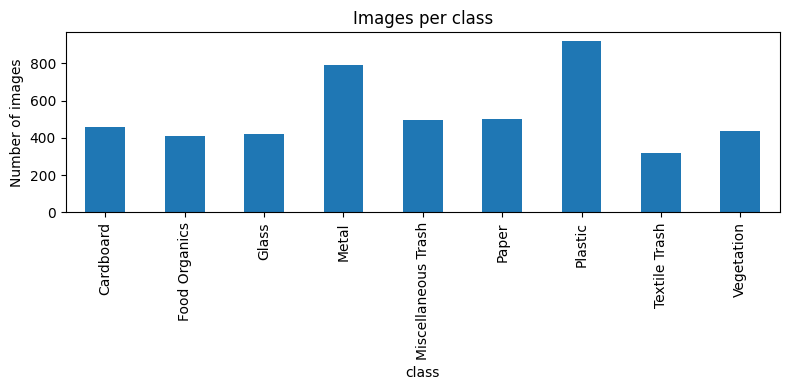

In [5]:
counts = df["class"].value_counts().sort_index()
print(counts)
print("Imbalance ratio (largest / smallest): %.2f" % (counts.max() / counts.min()))

ax = counts.plot(kind="bar", figsize=(8, 4), title="Images per class")
ax.set_ylabel("Number of images")
plt.tight_layout(); plt.show()

## 5. Data quality checks

In [6]:
ok = df[~df["corrupted"]]
print("Corrupted / unreadable files:", int(df["corrupted"].sum()))
print("Image modes:\n", ok["mode"].value_counts(), "\n")

sizes = ok.groupby(["width", "height"]).size().sort_values(ascending=False)
print("Distinct image sizes:", len(sizes))
print(sizes.head(10))

exact = ok[ok.duplicated("md5", keep=False)].sort_values("md5")
phash_int = ok["phash"].map(lambda x: int(x, 16))
near_counts = ok.assign(_phash=phash_int).groupby("_phash").size()
near_hashes = set(near_counts[near_counts > 1].index)
near_exact_hash = ok[phash_int.isin(near_hashes)].sort_values("phash")

group_sizes = ok.groupby("group_id").size()
multi_groups = set(group_sizes[group_sizes > 1].index)
near_groups = ok[ok["group_id"].isin(multi_groups)]
cross_class = near_groups.groupby("group_id")["class"].nunique()
print("\nFiles involved in exact duplicates (same bytes):", len(exact))
print("Files in repeated identical pHash values:", len(near_exact_hash))
print("Files in perceptual groups (pHash distance <=", PHASH_MAX_DISTANCE, "):", len(near_groups))
print("Perceptual groups spanning more than one class:", int((cross_class > 1).sum()))
if (cross_class > 1).any():
    print("\nREVIEW THESE POSSIBLE CROSS-LABEL GROUPS:")
    print(near_groups[near_groups["group_id"].isin(cross_class[cross_class > 1].index)][["group_id", "class", "relative_path", "phash"]].to_string(index=False))


Corrupted / unreadable files: 0
Image modes:
 mode
RGB    4752
Name: count, dtype: int64 

Distinct image sizes: 1
width  height
524    524       4752
dtype: int64

Files involved in exact duplicates (same bytes): 0
Files in repeated identical pHash values: 0
Files in perceptual groups (pHash distance <= 4 ): 24
Perceptual groups spanning more than one class: 4

REVIEW THESE POSSIBLE CROSS-LABEL GROUPS:
group_id         class                       relative_path            phash
  g01797     Cardboard         Cardboard/Cardboard_132.jpg b3f4cc8b32647133
  g01539 Food Organics Food Organics/Food Organics_150.jpg e6b099b366cc9923
  g04118         Metal                 Metal/Metal_127.jpg b3e6cc998c999919
  g01539         Metal                 Metal/Metal_326.jpg e6b9993366cc9903
  g01797         Metal                 Metal/Metal_559.jpg b3d0cccb32647333
  g03801         Metal                 Metal/Metal_738.jpg b0b4cbcb3c6c3233
  g03801       Plastic             Plastic/Plastic_204.jpg b0

## 6. Brightness by class
A first data-feature visualization for the assignment (brightness differs by material, e.g. glass and metal vs. textile).

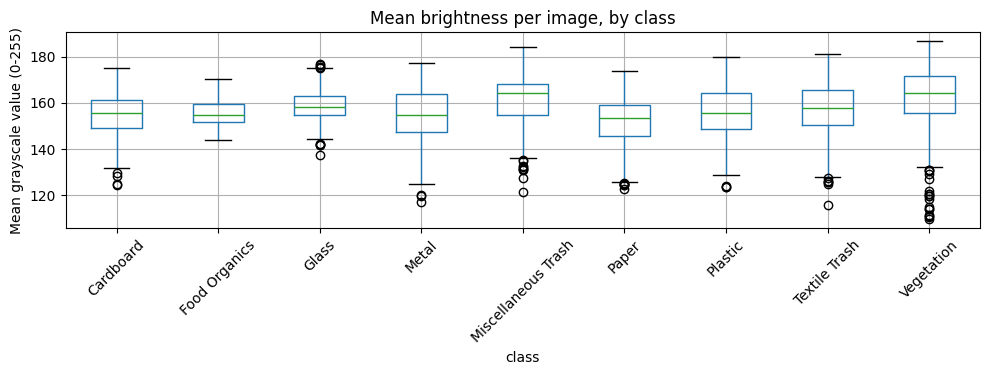

                      mean   std
class                           
Cardboard            155.0   8.6
Food Organics        155.8   5.0
Glass                158.8   6.4
Metal                154.9  11.0
Miscellaneous Trash  161.2   9.6
Paper                151.7  10.0
Plastic              156.0   9.8
Textile Trash        156.7  11.6
Vegetation           161.9  14.2


In [7]:
ok.boxplot(column="brightness", by="class", figsize=(10, 4), rot=45)
plt.suptitle(""); plt.title("Mean brightness per image, by class")
plt.ylabel("Mean grayscale value (0-255)")
plt.tight_layout(); plt.show()

print(ok.groupby("class")["brightness"].agg(["mean", "std"]).round(1))

## 7. Notes for the report (fill in after running)

- Final image count after removing corrupted files (if any):
- Class imbalance ratio:
- Exact duplicates and perceptual near-duplicate groups found:
- Any cross-class near-duplicate groups manually reviewed:
- Image size decision (resize target):
- What the brightness plot suggests (and what it does **not** prove):
- License: cite the UCI dataset record, but explicitly document the conflicting CC BY 4.0 vs CC BY-NC-SA 4.0 statements until clarified by the dataset authors.
